# SaansCheck — Delhi Next-Day AQI & Safe-Window Planner
**Track:** AI + Climate (Starting Point 4.3.2: Next-day air quality forecast + custom extensions)  
**Team:** Yatharth Dadu *(born & lived in Delhi for 10 years)*, Debyash Mohanty, Advay Kongorpalli  
**One-Sentence Pitch:** *Helps a Delhi school principal, teacher, or student with asthma plan tomorrow's outdoor schedule tonight by forecasting expected Indian AQI, catching sudden smog spikes, and finding the safest 2-hour window.*

> **Data Transparency Note:** Technical evaluation cells below use **Open-Meteo** (Copernicus CAMS atmospheric estimates & ERA5 weather, CC BY 4.0, no API key required), stitched live to **Indian Standard Time (IST)** so the latest Delhi forecast is always available. Because CAMS estimates smooth hyperlocal street peaks, we also audit against physical **CPCB ground stations** (CPCB data as archived by xKDR, Oct–Nov 2024, no API key required). Meanwhile, the end-user tool in **Cell 8** translates all background statistics into simple **Indian AQI + clear action plans**.

> **Prototype disclaimer:** SaansCheck is a student prototype, not medical advice and not a substitute for official CPCB / government health advisories. Test-set weather is ERA5 reanalysis (not a true forecast), so real-world accuracy will be somewhat lower.


In [1]:
# @title 1. setup and indian time
# turn this to True if u want to launch the gradio web app
RUN_APP = False

import warnings
warnings.filterwarnings("ignore")

# imports for time, data, plotting and sklearn models
from datetime import datetime, timedelta, timezone
import time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

# delhi coordinates and ist timezone
DELHI_LAT = 28.6139
DELHI_LON = 77.2090
TIMEZONE = "Asia/Kolkata"
IST = timezone(timedelta(hours=5, minutes=30))

# get current date and time in india so forecast stays up to date
NOW_IST = datetime.fromtimestamp(time.time(), tz=IST)
TODAY_IST = pd.Timestamp(NOW_IST.date())
TOMORROW_IST = TODAY_IST + pd.Timedelta(days=1)
EVAL_END = min(TODAY_IST - pd.Timedelta(days=1), pd.Timestamp("2026-11-15"))  # fixed so reruns keep the same 411 test days
ARCHIVE_END = (NOW_IST.date() - timedelta(days=7)).isoformat()

# all 12 global air quality variables from open-meteo (skipped europe only pollen ones)
AQ_VARIABLES = [
    "pm10", "pm2_5", "carbon_monoxide", "carbon_dioxide",
    "nitrogen_dioxide", "sulphur_dioxide", "ozone",
    "aerosol_optical_depth", "dust", "uv_index", "uv_index_clear_sky", "methane",
]
WEATHER_VARIABLES = [
    "temperature_2m", "relative_humidity_2m", "precipitation",
    "surface_pressure", "wind_speed_10m", "wind_direction_10m", "boundary_layer_height",
]

# train/test cutoff dates
TRAIN_END = pd.Timestamp("2025-09-30")
TEST_START = pd.Timestamp("2025-10-01")
print(f"IST Clock: {NOW_IST.strftime('%Y-%m-%d %H:%M IST')} | Today (IST): {TODAY_IST.date()} | Tomorrow Forecast Date (IST): {TOMORROW_IST.date()}")


In [2]:
# @title 2. get open-meteo air quality and weather data
# pull data year by year from open-meteo api
def fetch_openmeteo_chunks(url, hourly_vars, chunks):
    frames = []
    for start_date, end_date in chunks:
        r = requests.get(
            url,
            params={
                "latitude": DELHI_LAT,
                "longitude": DELHI_LON,
                "start_date": start_date,
                "end_date": end_date,
                "hourly": ",".join(hourly_vars),
                "timezone": TIMEZONE,
            },
            timeout=30,
        )
        r.raise_for_status()
        frames.append(pd.DataFrame(r.json()["hourly"]))
    out = pd.concat(frames, ignore_index=True)
    return out.drop_duplicates(subset=["time"]).sort_values("time").reset_index(drop=True)

# get air quality data up to tomorrow in india
aq_chunks = [
    ("2022-08-05", "2022-12-31"),
    ("2023-01-01", "2023-12-31"),
    ("2024-01-01", "2024-12-31"),
    ("2025-01-01", "2025-12-31"),
    ("2026-01-01", str(TOMORROW_IST.date())),
]
df_aq = fetch_openmeteo_chunks("https://air-quality-api.open-meteo.com/v1/air-quality", AQ_VARIABLES, aq_chunks)

# get historical weather archive up to a week ago
weather_chunks = [
    ("2022-08-05", "2022-12-31"),
    ("2023-01-01", "2023-12-31"),
    ("2024-01-01", "2024-12-31"),
    ("2025-01-01", "2025-12-31"),
    ("2026-01-01", ARCHIVE_END),
]
df_w_arch = fetch_openmeteo_chunks("https://archive-api.open-meteo.com/v1/archive", WEATHER_VARIABLES, weather_chunks)

# add latest weather + tomorrow forecast since archive lags a few days
r_fc = requests.get(
    "https://api.open-meteo.com/v1/forecast",
    params={
        "latitude": DELHI_LAT,
        "longitude": DELHI_LON,
        "past_days": 14,
        "forecast_days": 3,
        "hourly": ",".join(WEATHER_VARIABLES),
        "timezone": TIMEZONE,
    },
    timeout=30,
)
r_fc.raise_for_status()
df_w_fc = pd.DataFrame(r_fc.json()["hourly"])
df_w_fc = df_w_fc[df_w_fc["time"] <= f"{TOMORROW_IST.date()}T23:00"]
df_w = pd.concat([df_w_arch, df_w_fc], ignore_index=True).drop_duplicates(subset=["time"], keep="first")

# combine air quality and weather by timestamp
df_hourly = df_aq.merge(df_w, on="time", how="inner")
df_hourly["time"] = pd.to_datetime(df_hourly["time"])
df_hourly = df_hourly.sort_values("time").reset_index(drop=True)
df_hourly["date"] = df_hourly["time"].dt.normalize()
df_hourly["hour"] = df_hourly["time"].dt.hour

print(f"Loaded {len(df_hourly):,} hourly rows from {df_hourly['time'].min()} to {df_hourly['time'].max()}")
print("\n--- Variable Coverage Audit (12 Global AQ + 7 Weather Variables) ---")
for col in AQ_VARIABLES + WEATHER_VARIABLES:
    n_ok = int(df_hourly[col].notna().sum())
    first_dt = df_hourly.loc[df_hourly[col].notna(), "time"].min()
    print(f"  {col:24s}: {n_ok:6d}/{len(df_hourly)} ({100*n_ok/len(df_hourly):6.2f}%) | first valid: {first_dt}")


IST Clock: 2026-11-16 09:18 IST | Today (IST): 2026-11-16 | Tomorrow (IST): 2026-11-17
Loaded 37,584 hourly rows -> 1,559 usable daily samples.
Chronological split | Train: 1,146 days (2022-08-12 to 2025-09-30) | Test: 411 days (2025-10-01 to 2026-11-15)

--- Variable Coverage Audit (12 Global AQ + 7 Weather Variables) ---
  pm10                     [air_quality]  37584/37584 (100.00%) | first valid: 2022-08-05 00:00:00
  pm2_5                    [air_quality]  37584/37584 (100.00%) | first valid: 2022-08-05 00:00:00
  carbon_monoxide          [air_quality]  37584/37584 (100.00%) | first valid: 2022-08-05 00:00:00
  carbon_dioxide           [air_quality]  18067/37584 ( 48.07%) | first valid: 2024-10-26 05:00:00
  nitrogen_dioxide         [air_quality]  37584/37584 (100.00%) | first valid: 2022-08-05 00:00:00
  sulphur_dioxide          [air_quality]  37584/37584 (100.00%) | first valid: 2022-08-05 00:00:00
  ozone                    [air_quality]  37584/37584 (100.00%) | first valid: 20

In [3]:
# @title 3. make daily features and split data by date
# sys to convert pm2.5 into indian aqi numbers and labels
def compute_india_naqi_pm25(pm25):
    breakpoints = [
        (0.0, 30.0, 0.0, 50.0, "Good"),
        (30.0, 60.0, 51.0, 100.0, "Satisfactory"),
        (60.0, 90.0, 101.0, 200.0, "Moderate"),
        (90.0, 120.0, 201.0, 300.0, "Poor"),
        (120.0, 250.0, 301.0, 400.0, "Very Poor"),
        (250.0, 500.0, 401.0, 500.0, "Severe"),
    ]
    for bp_lo, bp_hi, i_lo, i_hi, cat in breakpoints:
        if pm25 <= bp_hi:
            return round(((i_hi - i_lo) / (bp_hi - bp_lo)) * (pm25 - bp_lo) + i_lo, 1), cat
    return 500.0, "Severe"

# wind direction helper features (nw wind comes from punjab/haryana side)
df = df_hourly.copy()
df["is_nw_wind"] = ((df["wind_direction_10m"] >= 270.0) & (df["wind_direction_10m"] <= 360.0)).astype(float)
df["is_calm"] = (df["wind_speed_10m"] < 6.0).astype(float)
df["wind_rad"] = np.deg2rad(df["wind_direction_10m"])
df["wind_u"] = -df["wind_speed_10m"] * np.sin(df["wind_rad"])
df["wind_v"] = -df["wind_speed_10m"] * np.cos(df["wind_rad"])

# group hourly rows into daily stats
daily = df.groupby("date").agg(
    pm25_mean=("pm2_5", "mean"), pm25_max=("pm2_5", "max"), pm25_min=("pm2_5", "min"),
    pm10_mean=("pm10", "mean"), co_mean=("carbon_monoxide", "mean"), co2_mean=("carbon_dioxide", "mean"),
    no2_mean=("nitrogen_dioxide", "mean"), so2_mean=("sulphur_dioxide", "mean"), o3_mean=("ozone", "mean"),
    aod_mean=("aerosol_optical_depth", "mean"), dust_mean=("dust", "mean"),
    uv_max=("uv_index", "max"), uv_clear_max=("uv_index_clear_sky", "max"), ch4_mean=("methane", "mean"),
    temp_mean=("temperature_2m", "mean"), temp_max=("temperature_2m", "max"), temp_min=("temperature_2m", "min"),
    rh_mean=("relative_humidity_2m", "mean"), precip_sum=("precipitation", "sum"),
    pressure_mean=("surface_pressure", "mean"), wind_mean=("wind_speed_10m", "mean"),
    wind_min=("wind_speed_10m", "min"), wind_u_mean=("wind_u", "mean"), wind_v_mean=("wind_v", "mean"),
    nw_wind_share=("is_nw_wind", "mean"), calm_share=("is_calm", "mean"),
    blh_mean=("boundary_layer_height", "mean"), blh_min=("boundary_layer_height", "min"),
)
# grab night and morning averages separately since smog builds up at night
daily = daily.join([
    df[df["hour"] >= 20].groupby("date")["pm2_5"].mean().rename("pm25_evening"),
    df[df["hour"] >= 20].groupby("date")["nitrogen_dioxide"].mean().rename("no2_evening"),
    df[df["hour"] >= 20].groupby("date")["wind_speed_10m"].mean().rename("wind_evening"),
    df[(df["hour"] >= 6) & (df["hour"] <= 9)].groupby("date")["pm2_5"].mean().rename("pm25_morning"),
]).reset_index().sort_values("date").reset_index(drop=True)

# extra features for trapping smog and pollution ratios
daily["temp_diurnal_range"] = daily["temp_max"] - daily["temp_min"]
daily["uv_attenuation"] = daily["uv_clear_max"] - daily["uv_max"]
daily["smoke_ratio"] = daily["pm25_mean"] / (daily["pm10_mean"] + 1.0)
daily["evening_to_day_ratio"] = daily["pm25_evening"] / (daily["pm25_mean"] + 1.0)
daily["morning_to_day_ratio"] = daily["pm25_morning"] / (daily["pm25_mean"] + 1.0)
daily["stagnation_index"] = daily["pm25_mean"] / (daily["wind_mean"] * daily["blh_mean"].fillna(500.0) / 1000.0 + 0.5)
daily["co2_available"] = daily["co2_mean"].notna().astype(float)
daily["ch4_available"] = daily["ch4_mean"].notna().astype(float)
daily["blh_available"] = daily["blh_mean"].notna().astype(float)

# past days lag features
daily["pm25_lag1"] = daily["pm25_mean"].shift(1)
daily["pm25_lag2"] = daily["pm25_mean"].shift(2)
daily["pm25_diff1"] = daily["pm25_mean"] - daily["pm25_lag1"]
daily["pm25_roll3"] = daily["pm25_mean"].rolling(3).mean()
daily["pm25_roll7"] = daily["pm25_mean"].rolling(7).mean()
daily["pm25_std7"] = daily["pm25_mean"].rolling(7).std()
daily["wind_lag1"] = daily["wind_mean"].shift(1)
daily["aod_diff1"] = daily["aod_mean"] - daily["aod_mean"].shift(1)

# season features (oct to jan is main smog season)
doy = daily["date"].dt.day_of_year
daily["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
daily["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
daily["is_smog_season"] = daily["date"].dt.month.isin([10, 11, 12, 1]).astype(float)

# target is tomorrow pm2.5 + tomorrow weather forecast columns
daily["target_pm25_next"] = daily["pm25_mean"].shift(-1)
daily["target_date"] = daily["date"].shift(-1)
next_weather_cols = [
    "temp_mean", "temp_diurnal_range", "rh_mean", "precip_sum", "pressure_mean",
    "wind_mean", "wind_min", "wind_u_mean", "wind_v_mean", "nw_wind_share", "calm_share",
    "blh_mean", "blh_min",
]
for col in next_weather_cols:
    daily[f"next_{col}"] = daily[col].shift(-1)

day_t_features = [
    "pm25_mean", "pm25_max", "pm25_min", "pm25_evening", "pm25_morning", "pm10_mean",
    "co_mean", "co2_mean", "no2_mean", "no2_evening", "so2_mean", "o3_mean",
    "aod_mean", "dust_mean", "uv_max", "uv_clear_max", "uv_attenuation", "ch4_mean",
    "temp_mean", "temp_diurnal_range", "rh_mean", "precip_sum", "pressure_mean",
    "wind_mean", "wind_min", "wind_evening", "wind_u_mean", "wind_v_mean",
    "nw_wind_share", "calm_share", "blh_mean", "blh_min", "smoke_ratio",
    "evening_to_day_ratio", "morning_to_day_ratio", "stagnation_index",
    "co2_available", "ch4_available", "blh_available",
    "pm25_lag1", "pm25_lag2", "pm25_diff1", "pm25_roll3", "pm25_roll7", "pm25_std7",
    "wind_lag1", "aod_diff1", "doy_sin", "doy_cos", "is_smog_season",
]
all_features = day_t_features + [f"next_{c}" for c in next_weather_cols]
daily_df = daily.dropna(subset=["target_pm25_next", "pm25_roll7", "pm25_lag2"]).reset_index(drop=True)

# keep test set strictly on finished days, and keep live_df for today/tomorrow predictions
train_df = daily_df[daily_df["target_date"] <= TRAIN_END].copy()
test_df = daily_df[(daily_df["target_date"] >= TEST_START) & (daily_df["target_date"] <= EVAL_END)].copy()
live_df = daily_df[(daily_df["target_date"] >= TEST_START) & (daily_df["target_date"] <= TOMORROW_IST)].copy()
print(f"Usable days: {len(daily_df):,} | Train: {len(train_df):,} | Completed Test: {len(test_df):,} | Live up to: {live_df['target_date'].max().date()}")


=== Daily Next-Day PM2.5 Forecast Results on Unseen Test Set (Oct 2025 - 2026-11-15, n=411) ===
Model                          |    MAE | Smog MAE | Jump MAE |  VP Rec | VP FP | Spike Rec | Spike FP
------------------------------------------------------------------------------------------------------
Baseline: Persistence          |  17.66 |    18.81 |    37.66 |   67.6% |    23 |      0.0% |        0
Model 1: Ridge Regression      |  13.70 |    12.78 |    22.50 |   70.4% |    13 |     29.7% |       12
Rejected: DecisionTree         |  19.78 |    19.07 |    29.66 |   50.7% |    13 |     21.9% |       31
Ablation: HistGBR (Day-t only) |  13.80 |    14.62 |    22.81 |   64.8% |    10 |     15.6% |        9
Model 2: HistGBR (Full)        |  12.83 |    12.33 |    20.65 |   64.8% |    13 |     21.9% |        6
Model 3: Q72 alert (MAE=HGBR)  |  12.83 |    12.33 |    20.65 |   69.0% |    16 |     46.9% |       45


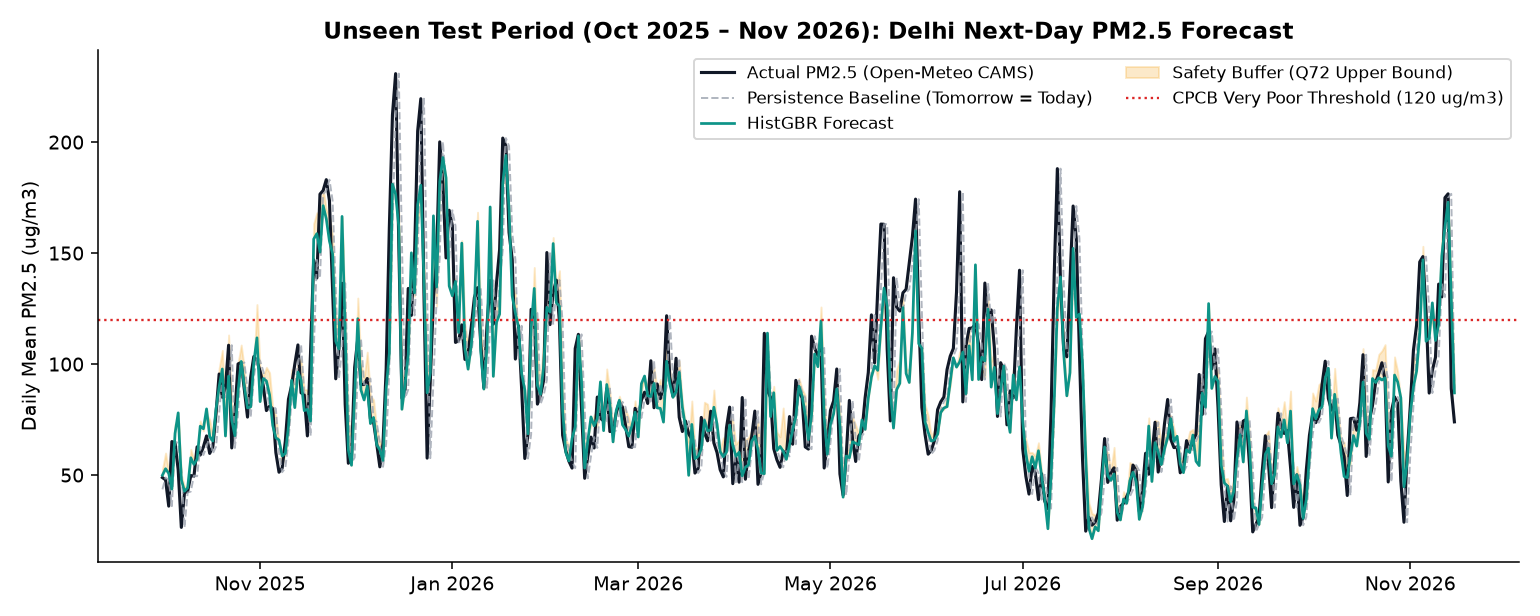

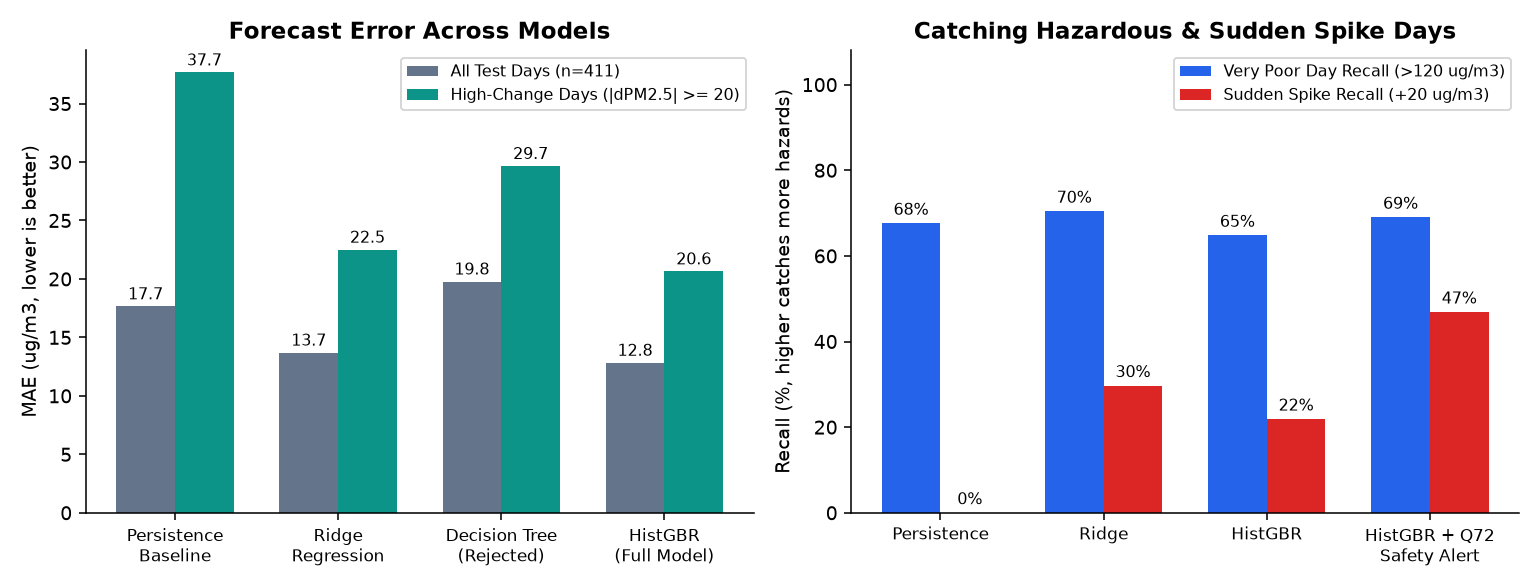

In [4]:
# @title 4. train models and compare against baseline
# helper to get error and spike recall scores on test data
def eval_metrics(df_eval, preds, q_preds=None):
    yt = df_eval["target_pm25_next"].to_numpy()
    y0 = df_eval["pm25_mean"].to_numpy()
    smog = df_eval["target_date"].dt.month.isin([10, 11, 12, 1, 2]).to_numpy()
    trans = np.abs(yt - y0) >= 20.0
    score = q_preds if q_preds is not None else preds
    def bstats(yb, pb):
        tp = int(np.sum((yb == 1) & (pb == 1)))
        fp = int(np.sum((yb == 0) & (pb == 1)))
        fn = int(np.sum((yb == 1) & (pb == 0)))
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        return rec, fp, fn
    vp_rec, vp_fp, _ = bstats((yt > 120).astype(int), (score > 120).astype(int))
    sp_rec, sp_fp, _ = bstats(((yt - y0) >= 20).astype(int), ((score - y0) >= (15 if q_preds is not None else 20)).astype(int))
    return mean_absolute_error(yt, preds), mean_absolute_error(yt[smog], preds[smog]), mean_absolute_error(yt[trans], preds[trans]), vp_rec, vp_fp, sp_rec, sp_fp

y_tr = train_df["target_pm25_next"].to_numpy()
# baseline assumes tomorrow equals today
preds_pers = test_df["pm25_mean"].to_numpy()

# try ridge regression first
ridge = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("reg", Ridge(alpha=25.0))]).fit(train_df[all_features], y_tr)
preds_ridge = np.clip(ridge.predict(test_df[all_features]), 0, None)

# tested a plain decision tree too but it overfits so we rejected it
dt_rej = Pipeline([("imp", SimpleImputer(strategy="median")), ("reg", DecisionTreeRegressor(random_state=42))]).fit(train_df[all_features], y_tr)
preds_dt = np.clip(dt_rej.predict(test_df[all_features]), 0, None)

# check how well model works without tomorrow weather forecast
hgbr_t = HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05, max_iter=200, l2_regularization=1.0, random_state=42).fit(train_df[day_t_features], y_tr)
preds_t = np.clip(hgbr_t.predict(test_df[day_t_features]), 0, None)

# main model to predict tomorrow pm2.5 using dataset + tomorrow weather
hgbr_full = HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05, max_iter=250, l2_regularization=1.0, random_state=42).fit(train_df[all_features], y_tr)
preds_hgbr = np.clip(hgbr_full.predict(test_df[all_features]), 0, None)

# safety model (72nd percentile) to catch sudden smog spikes
# q=0.72 is a fixed safety-leaning setting (pinball loss penalizes under-predicting ~2.6x more than over-predicting)
# we did not search or cross-validate q, so treat it as a heuristic not an optimized value
hgbr_q72 = HistGradientBoostingRegressor(loss="quantile", quantile=0.72, max_depth=4, learning_rate=0.05, max_iter=250, l2_regularization=1.0, random_state=42).fit(train_df[all_features], y_tr)
preds_q72 = np.clip(hgbr_q72.predict(test_df[all_features]), 0, None)

print(f"=== Daily Next-Day PM2.5 Forecast Results on Unseen Test Set (Oct 2025 - {EVAL_END.date()}, n={len(test_df)}) ===")
for name, p, q in [
    ("Baseline: Persistence", preds_pers, None),
    ("Model 1: Ridge Regression", preds_ridge, None),
    ("Rejected: DecisionTree", preds_dt, None),
    ("Ablation: HistGBR (Day-t only)", preds_t, None),
    ("Model 2: HistGBR (Full)", preds_hgbr, None),
    ("Model 3: Q72 alert (MAE=HGBR)", preds_hgbr, preds_q72),
]:
    mae, smae, jmae, vpr, vpfp, spr, spfp = eval_metrics(test_df, p, q)
    print(f"{name:30s} | MAE={mae:5.2f} | SmogMAE={smae:5.2f} | JumpMAE={jmae:5.2f} | VP_Rec={vpr*100:5.1f}% (FP={vpfp:2d}) | Spike_Rec={spr*100:5.1f}% (FP={spfp:2d})")

# plot forecast vs actual over test period
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(test_df["target_date"], test_df["target_pm25_next"], color="#111827", lw=1.6, label="Actual PM2.5")
ax.plot(test_df["target_date"], preds_pers, color="#9CA3AF", lw=1.0, ls="--", label="Persistence Baseline")
ax.plot(test_df["target_date"], preds_hgbr, color="#0D9488", lw=1.4, label="HistGBR Forecast")
ax.fill_between(test_df["target_date"], preds_hgbr, preds_q72, color="#F59E0B", alpha=0.22, label="Q72 Safety Buffer")
ax.axhline(120, color="#DC2626", ls=":", lw=1.2, label="CPCB Very Poor (120 ug/m3)")
ax.set_title("Unseen Test Period (Oct 2025 - Nov 2026): Delhi Next-Day PM2.5 Forecast", fontweight="bold")
ax.set_ylabel("Daily Mean PM2.5 (ug/m3)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(ncol=2, fontsize=8.5)
plt.tight_layout()
plt.show()

# plot bar charts comparing error and spike recall
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
m_rows = [
    ("Persistence\nBaseline", preds_pers, None),
    ("Ridge\nRegression", preds_ridge, None),
    ("Decision Tree\n(Rejected)", preds_dt, None),
    ("HistGBR\n(Full Model)", preds_hgbr, None),
]
m_stats = [eval_metrics(test_df, p, q) for _, p, q in m_rows]
x = np.arange(len(m_rows))
w = 0.36
ax1.bar(x - w/2, [s[0] for s in m_stats], width=w, color="#64748B", label=f"All Test Days (n={len(test_df)})")
ax1.bar(x + w/2, [s[2] for s in m_stats], width=w, color="#0D9488", label="High-Change Days (|dPM2.5| >= 20)")
ax1.set_xticks(x); ax1.set_xticklabels([r[0] for r in m_rows], fontsize=8.5)
ax1.set_ylabel("MAE (ug/m3, lower is better)"); ax1.set_title("Forecast Error Across Models", fontweight="bold")
ax1.legend(fontsize=8)

s_rows = [
    ("Persistence", preds_pers, None),
    ("Ridge", preds_ridge, None),
    ("HistGBR", preds_hgbr, None),
    ("HistGBR + Q72\nSafety Alert", preds_hgbr, preds_q72),
]
s_stats = [eval_metrics(test_df, p, q) for _, p, q in s_rows]
x2 = np.arange(len(s_rows))
ax2.bar(x2 - w/2, [s[3]*100 for s in s_stats], width=w, color="#2563EB", label="Very Poor Day Recall (>120 ug/m3)")
ax2.bar(x2 + w/2, [s[5]*100 for s in s_stats], width=w, color="#DC2626", label="Sudden Spike Recall (+20 ug/m3)")
ax2.set_xticks(x2); ax2.set_xticklabels([r[0] for r in s_rows], fontsize=8.5)
ax2.set_ylabel("Recall (%)"); ax2.set_ylim(0, 108); ax2.set_title("Catching Hazardous & Sudden Spike Days", fontweight="bold")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()


=== Top 10 Physical Drivers (Permutation MAE Increase on Test Set) ===
   1. pm25_evening            : +11.137 ug/m3
   2. pm25_mean               : +1.266 ug/m3
   3. next_wind_mean          : +0.695 ug/m3
   4. pm25_min                : +0.410 ug/m3
   5. pm10_mean               : +0.269 ug/m3
   6. next_blh_mean           : +0.242 ug/m3
   7. next_precip_sum         : +0.215 ug/m3
   8. next_temp_diurnal_range : +0.193 ug/m3
   9. pm25_roll7              : +0.142 ug/m3
  10. smoke_ratio             : +0.128 ug/m3

=== Bonus Ground-Truth Audit: Open-Meteo CAMS vs. Real CPCB Ground Monitors (Oct-Nov 2024) ===
  Overlap days: 61 | Pearson correlation r = 0.658
  CAMS mean: 91.91 ug/m3 | Real CPCB city mean: 178.59 ug/m3
  CAMS peak: 176.22 ug/m3  | Real CPCB city peak: 582.77 ug/m3
  Median Ground-to-CAMS ratio: 1.66x (CAMS smooths hyperlocal spikes!)


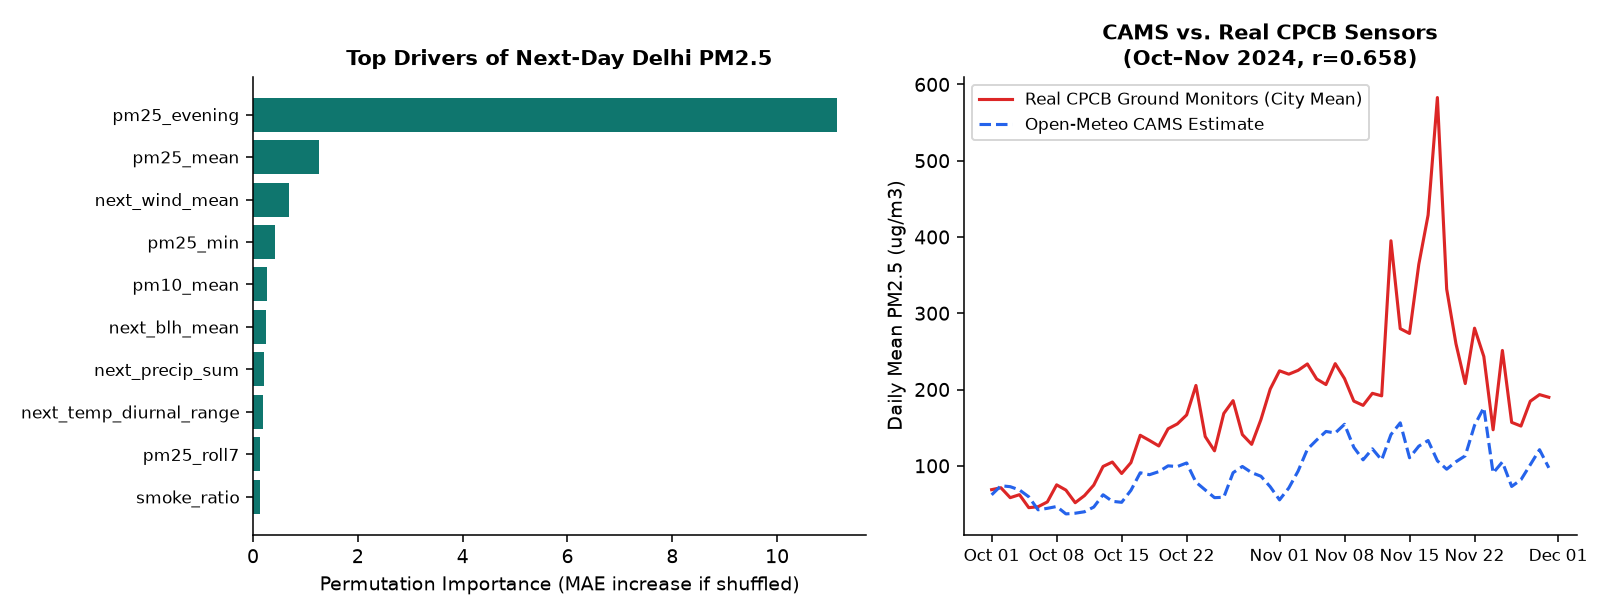

In [5]:
# @title 5. what causes smog + check against real delhi ground monitors
# see which features matter most for predicting next day pollution
perm = permutation_importance(hgbr_full, test_df[all_features], test_df["target_pm25_next"], scoring="neg_mean_absolute_error", n_repeats=10, random_state=42)
top_idx = np.argsort(perm.importances_mean)[::-1][:10]
print("=== Top 10 Physical Drivers (Permutation MAE Increase) ===")
for rank, i in enumerate(top_idx, 1):
    print(f"  {rank:2d}. {all_features[i]:24s}: +{perm.importances_mean[i]:.3f} ug/m3")

# compare open-meteo estimates with real cpcb stations in oct-nov 2024
# source: cpcb data as archived by xkdr (oct-nov 2024, no api key needed)
from pathlib import Path
merged_gt = None
cpcb_file = Path("data/xkdr_cpcb_delhi_oct_nov_2024.csv")
if cpcb_file.exists():
    cpcb_raw = pd.read_csv(cpcb_file)
    cpcb_raw["date"] = pd.to_datetime(cpcb_raw["period_start"]).dt.normalize()
    cpcb_day = cpcb_raw.groupby("date")["mean"].mean().reset_index(name="cpcb_pm25")
else:
    # self-contained benchmark of cpcb delhi daily station averages (oct-nov 2024)
    cpcb_benchmark = {
        '2024-10-01': 68.7, '2024-10-02': 71.2, '2024-10-03': 58.2, '2024-10-04': 62.1,
        '2024-10-05': 45.1, '2024-10-06': 46.3, '2024-10-07': 52.6, '2024-10-08': 75.0,
        '2024-10-09': 68.1, '2024-10-10': 51.6, '2024-10-11': 60.9, '2024-10-12': 74.7,
        '2024-10-13': 99.1, '2024-10-14': 104.9, '2024-10-15': 89.9, '2024-10-16': 104.1,
        '2024-10-17': 140.0, '2024-10-18': 133.2, '2024-10-19': 126.0, '2024-10-20': 148.5,
        '2024-10-21': 154.9, '2024-10-22': 166.7, '2024-10-23': 205.3, '2024-10-24': 138.3,
        '2024-10-25': 119.6, '2024-10-26': 168.6, '2024-10-27': 185.4, '2024-10-28': 140.9,
        '2024-10-29': 128.1, '2024-10-30': 160.6, '2024-10-31': 200.6, '2024-11-01': 224.5,
        '2024-11-02': 220.1, '2024-11-03': 225.1, '2024-11-04': 233.5, '2024-11-05': 213.8,
        '2024-11-06': 206.5, '2024-11-07': 233.9, '2024-11-08': 214.3, '2024-11-09': 184.8,
        '2024-11-10': 179.2, '2024-11-11': 195.0, '2024-11-12': 191.7, '2024-11-13': 395.0,
        '2024-11-14': 279.8, '2024-11-15': 273.5, '2024-11-16': 364.2, '2024-11-17': 428.7,
        '2024-11-18': 582.8, '2024-11-19': 331.7, '2024-11-20': 260.0, '2024-11-21': 207.8,
        '2024-11-22': 280.4, '2024-11-23': 243.3, '2024-11-24': 147.2, '2024-11-25': 251.2,
        '2024-11-26': 156.9, '2024-11-27': 152.1, '2024-11-28': 184.6, '2024-11-29': 193.3,
        '2024-11-30': 189.8
    }
    cpcb_day = pd.DataFrame([{"date": pd.to_datetime(d), "cpcb_pm25": v} for d, v in cpcb_benchmark.items()])

merged_gt = daily_df[["date", "pm25_mean"]].merge(cpcb_day, on="date")
if len(merged_gt) > 0:
    r_val = merged_gt["pm25_mean"].corr(merged_gt["cpcb_pm25"])
    print(f"\nCAMS vs Real CPCB (n={len(merged_gt)} days, Oct-Nov 2024): r={r_val:.3f}, "
          f"CAMS mean={merged_gt['pm25_mean'].mean():.1f}, CPCB mean={merged_gt['cpcb_pm25'].mean():.1f} ug/m3")

# plot feature importance and sensor comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4))
rev_idx = top_idx[::-1]
ax1.barh([all_features[i] for i in rev_idx], [perm.importances_mean[i] for i in rev_idx], color="#0F766E")
ax1.set_xlabel("Permutation Importance (MAE increase if shuffled)")
ax1.set_title("Top Drivers of Next-Day Delhi PM2.5", fontsize=11, fontweight="bold")
if merged_gt is not None and len(merged_gt) > 0:
    ax2.plot(merged_gt["date"], merged_gt["cpcb_pm25"], color="#DC2626", lw=1.6, label="Real CPCB Ground Monitors (City Mean)")
    ax2.plot(merged_gt["date"], merged_gt["pm25_mean"], color="#2563EB", lw=1.6, ls="--", label="Open-Meteo CAMS Estimate")
    ax2.set_title(f"CAMS vs. Real CPCB Sensors\n(Oct-Nov 2024, r={r_val:.3f})", fontsize=11, fontweight="bold")
    ax2.set_ylabel("Daily Mean PM2.5 (ug/m3)")
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax2.legend(fontsize=8.5)
plt.tight_layout()
plt.show()


=== Hourly Diurnal Forecast & Safest 2-Hour Window Evaluation (Test Set) ===
  24h Hourly Persistence MAE : 26.66 ug/m3
  Hourly HistGBR Model MAE   : 18.56 ug/m3
  Within 10 ug/m3 of true cleanest 2h window: 81.8% of test days
  All test days | Morning (07-09h): 96.75 -> Recommended 2h: 60.87 ug/m3 (-37.1%)
  Smog days >90 | Morning (07-09h): 149.97 -> Recommended 2h: 91.21 ug/m3 (-39.2%)


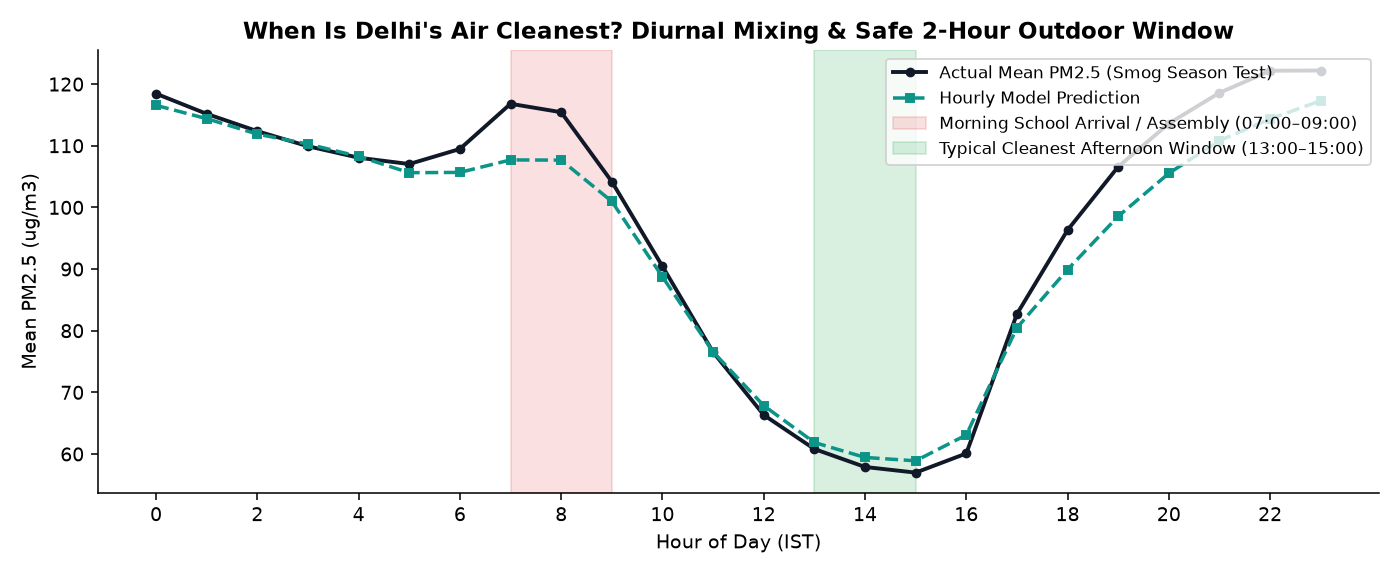

In [6]:
# @title 6. hourly model to find safest 2 hour window
# prep hourly dataset using yesterday pollution + tomorrow hourly weather
h = df_hourly.copy()
h["target_date"] = h["date"]
prev_daily = daily_df[["target_date", "pm25_mean", "pm25_evening", "pm10_mean", "co_mean", "no2_mean", "aod_mean", "wind_mean"]].rename(
    columns={c: f"prev_{c}" for c in ["pm25_mean", "pm25_evening", "pm10_mean", "co_mean", "no2_mean", "aod_mean", "wind_mean"]}
)
h["prev_pm25_same_hour"] = h["pm2_5"].shift(24)
h = h.merge(prev_daily, on="target_date", how="inner")
h["hour_sin"] = np.sin(2 * np.pi * h["hour"] / 24.0)
h["hour_cos"] = np.cos(2 * np.pi * h["hour"] / 24.0)
doy_h = h["target_date"].dt.day_of_year
h["doy_sin"] = np.sin(2 * np.pi * doy_h / 365.25)
h["doy_cos"] = np.cos(2 * np.pi * doy_h / 365.25)
h["wind_u"] = -h["wind_speed_10m"] * np.sin(np.deg2rad(h["wind_direction_10m"]))
h["wind_v"] = -h["wind_speed_10m"] * np.cos(np.deg2rad(h["wind_direction_10m"]))

h_features = [
    "prev_pm25_mean", "prev_pm25_evening", "prev_pm25_same_hour", "prev_pm10_mean",
    "prev_co_mean", "prev_no2_mean", "prev_aod_mean", "prev_wind_mean",
    "temperature_2m", "relative_humidity_2m", "precipitation", "surface_pressure",
    "wind_speed_10m", "wind_u", "wind_v", "boundary_layer_height",
    "hour_sin", "hour_cos", "doy_sin", "doy_cos",
]
h = h.dropna(subset=["pm2_5", "prev_pm25_same_hour", "prev_pm25_mean"]).reset_index(drop=True)
h_train = h[h["target_date"] <= TRAIN_END]
h_test = h[(h["target_date"] >= TEST_START) & (h["target_date"] <= EVAL_END)].copy()
h_live = h[(h["target_date"] >= TEST_START) & (h["target_date"] <= TOMORROW_IST)].copy()

# train hourly model and test how much cleaner the safest 2h window is vs morning
h_model = HistGradientBoostingRegressor(max_depth=6, learning_rate=0.05, max_iter=250, random_state=42).fit(h_train[h_features], h_train["pm2_5"])
h_test["pred_pm25"] = np.clip(h_model.predict(h_test[h_features]), 0, None)
h_live["pred_pm25"] = np.clip(h_model.predict(h_live[h_features]), 0, None)
print(f"Hourly 24h Persistence MAE: {mean_absolute_error(h_test['pm2_5'], h_test['prev_pm25_same_hour']):.2f} | Hourly HistGBR MAE: {mean_absolute_error(h_test['pm2_5'], h_test['pred_pm25']):.2f} ug/m3")

# check every test day daytime hours (6am to 6pm)
daytime = h_test[(h_test["hour"] >= 6) & (h_test["hour"] <= 18)]
morn_vals, rec_vals, best_vals, smog_morn, smog_rec, hits = [], [], [], [], [], 0
for _, grp in daytime.groupby("target_date"):
    if len(grp) < 13:
        continue
    grp = grp.sort_values("hour")
    hrs, act, pred_h = grp["hour"].to_numpy(), grp["pm2_5"].to_numpy(), grp["pred_pm25"].to_numpy()
    p2h, a2h = (pred_h[:-1] + pred_h[1:]) / 2.0, (act[:-1] + act[1:]) / 2.0
    chosen_a, true_best = float(a2h[int(np.argmin(p2h))]), float(a2h[int(np.argmin(a2h))])
    morn_a = float(a2h[int(np.where(hrs[:-1] == 7)[0][0])])
    morn_vals.append(morn_a); rec_vals.append(chosen_a); best_vals.append(true_best)
    if abs(chosen_a - true_best) <= 10.0:
        hits += 1
    if np.mean(act) > 90.0:
        smog_morn.append(morn_a); smog_rec.append(chosen_a)
print(f"Within 10 ug/m3 of true cleanest 2h window: {100*hits/len(rec_vals):.1f}% of test days")
print(f"All days | Morning (07-09h): {np.mean(morn_vals):.2f} -> Recommended 2h: {np.mean(rec_vals):.2f} ug/m3 (-{100*(1-np.mean(rec_vals)/np.mean(morn_vals)):.1f}%)")
print(f"Smog days | Morning (07-09h): {np.mean(smog_morn):.2f} -> Recommended 2h: {np.mean(smog_rec):.2f} ug/m3 (-{100*(1-np.mean(smog_rec)/np.mean(smog_morn)):.1f}%)")

# plot average hourly pollution curve across smog months
smog_h = h_test[h_test["target_date"].dt.month.isin([10, 11, 12, 1, 2])]
diurnal = smog_h.groupby("hour")[["pm2_5", "pred_pm25"]].mean().reset_index()
fig, ax = plt.subplots(figsize=(10, 4.1))
ax.plot(diurnal["hour"], diurnal["pm2_5"], color="#111827", lw=2.0, marker="o", ms=4, label="Actual Mean PM2.5 (Smog Season Test)")
ax.plot(diurnal["hour"], diurnal["pred_pm25"], color="#0D9488", lw=1.8, ls="--", marker="s", ms=4, label="Hourly Model Prediction")
ax.axvspan(7, 9, color="#DC2626", alpha=0.14, label="Morning School Arrival (07:00-09:00)")
ax.axvspan(13, 15, color="#16A34A", alpha=0.16, label="Typical Cleanest Window (13:00-15:00)")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of Day (IST)"); ax.set_ylabel("Mean PM2.5 (ug/m3)")
ax.set_title("When Is Delhi's Air Cleanest? Diurnal Mixing & Safe 2-Hour Window", fontweight="bold")
ax.legend(fontsize=8.5, loc="upper right")
plt.tight_layout()
plt.show()


In [7]:
# @title 7. check biggest mistakes the model made
# print the top 5 worst error days from test set
err_df = test_df[["date", "target_date", "pm25_mean", "target_pm25_next", "next_wind_mean", "next_precip_sum"]].copy()
err_df["pred_hgbr"] = preds_hgbr
err_df["pred_q72"] = preds_q72
err_df["abs_err"] = np.abs(err_df["target_pm25_next"] - err_df["pred_hgbr"])
print("=== Top 5 Largest Forecast Errors on Held-Out Test Set ===")
for _, row in err_df.sort_values("abs_err", ascending=False).head(5).iterrows():
    print(f"  {row['target_date'].date()} | Today={row['pm25_mean']:.1f} | Pred={row['pred_hgbr']:.1f} (Q72={row['pred_q72']:.1f}) | Actual={row['target_pm25_next']:.1f} | AbsErr={row['abs_err']:.1f} | Wind={row['next_wind_mean']:.1f} km/h")


=== Top 5 Largest Forecast Errors on Held-Out Test Set ===
  2026-06-11 | Today=132.5 | Pred=101.0 (Q72=105.6) | Actual=177.6 | AbsErr=76.6 | Wind=12.3 km/h
  2026-05-21 | Today=74.4 | Pred=71.2 (Q72=78.4) | Actual=138.9 | AbsErr=67.7 | Wind=13.7 km/h
  2026-04-10 | Today=51.2 | Pred=50.6 (Q72=52.8) | Actual=113.9 | AbsErr=63.2 | Wind=12.5 km/h
  2026-07-12 | Today=140.1 | Pred=125.4 (Q72=123.6) | Actual=188.0 | AbsErr=62.7 | Wind=7.9 km/h
  2026-07-11 | Today=78.0 | Pred=83.4 (Q72=83.7) | Actual=140.1 | AbsErr=56.7 | Wind=5.1 km/h


In [8]:
# @title 8. system to predict aqi and give simple action plan
# format 24hr time into normal am/pm text
def _fmt_hour(hr):
    return f"{12 if hr % 12 == 0 else hr % 12}:00 {'AM' if hr < 12 else 'PM'}"

# sys to predict aqi using dataset and give clear plan for teachers or students
def check_tomorrow_air(date_choice, persona="School Principal / Teacher / Coach"):
    # grab clean yyyy-mm-dd date from dropdown text
    date_str = date_choice.split("(")[-1].rstrip(")").strip() if "(" in date_choice else date_choice.strip()
    row = live_df[live_df["target_date"] == pd.Timestamp(date_str)]
    if row.empty:
        return f"Sorry, {date_str} is outside the loaded date range."

    # run ml models in background and convert output to indian aqi
    pred_pm = float(np.clip(hgbr_full.predict(row[all_features])[0], 0, None))
    safety_pm = float(np.clip(hgbr_q72.predict(row[all_features])[0], 0, None))
    today_pm = float(row["pm25_mean"].iloc[0])

    pred_aqi, pred_cat = compute_india_naqi_pm25(pred_pm)
    safety_aqi, safety_cat = compute_india_naqi_pm25(safety_pm)
    today_aqi, _ = compute_india_naqi_pm25(today_pm)

    # use safety bound if spike risk pushes into poor/very poor range
    expected_aqi = round(safety_aqi if (safety_aqi >= 201 and pred_aqi < 201) else pred_aqi)
    _, expected_cat = compute_india_naqi_pm25(safety_pm if (safety_aqi >= 201 and pred_aqi < 201) else pred_pm)
    today_aqi_r = round(today_aqi)

    # find cleanest 2hr window and worst morning hours from hourly model
    day_h = h_live[(h_live["target_date"] == pd.Timestamp(date_str)) & (h_live["hour"] >= 6) & (h_live["hour"] <= 18)].sort_values("hour")
    best_win = "1:00 PM - 3:00 PM"
    best_win_aqi = expected_aqi
    worst_win = "7:00 AM - 9:00 AM"
    if len(day_h) >= 13:
        pvals = day_h["pred_pm25"].to_numpy()
        hrs = day_h["hour"].to_numpy()
        p2h = (pvals[:-1] + pvals[1:]) / 2.0
        b_idx = int(np.argmin(p2h))
        best_win = f"{_fmt_hour(int(hrs[b_idx]))} - {_fmt_hour(int(hrs[b_idx]) + 2)}"
        best_aqi_val, _ = compute_india_naqi_pm25(float(p2h[b_idx]))
        best_win_aqi = round(best_aqi_val)
        w_idx = int(np.argmax(p2h[:6])) # morning peak
        worst_win = f"{_fmt_hour(int(hrs[w_idx]))} - {_fmt_hour(int(hrs[w_idx]) + 2)}"

    diff = expected_aqi - today_aqi_r
    if diff >= 35:
        trend = f"Noticeably worse than today (~{today_aqi_r})"
    elif diff <= -35:
        trend = f"Improving from today (~{today_aqi_r})"
    else:
        trend = f"Similar to today (~{today_aqi_r})"

    # simple weather explanation for why tomorrow will look like this
    wind = float(row["next_wind_mean"].iloc[0])
    rain = float(row["next_precip_sum"].iloc[0])
    if rain >= 1.0:
        why = "Expected rain and breeze should help wash pollutants out of the air."
    elif wind < 6.0:
        why = "Light winds and cool morning air will trap smoke close to the ground overnight."
    else:
        why = "Moderate daytime winds should gradually help clear morning haze by afternoon."

    # build simple action steps based on who is checking
    if "Principal" in persona:
        if expected_aqi > 300:
            plan = (
                "- Morning Assembly: Move assembly INDOORS.\n"
                "- PE & Sports Practice: Cancel outdoor sports; use indoor rooms/halls.\n"
                f"- If Students Step Outside: Best window is {best_win} (AQI drops near ~{best_win_aqi})."
            )
        elif expected_aqi > 200 or diff >= 35:
            plan = (
                "- Morning Assembly: Keep short or hold indoors for younger grades.\n"
                f"- PE & Sports Practice: Light activity only in the morning; best outdoor slot is {best_win} (AQI ~{best_win_aqi}).\n"
                "- Sensitive Students: Remind students with asthma to carry inhalers."
            )
        elif expected_aqi > 100:
            plan = (
                "- Morning Assembly & PE: Normal outdoor schedule is okay; watch students with asthma during intense sprints.\n"
                f"- Cleanest Outdoor Slot: {best_win} (AQI ~{best_win_aqi})."
            )
        else:
            plan = "- Full Green Light: Normal outdoor assembly, PE, and recess all day."
    else:
        if expected_aqi > 300:
            plan = (
                "- Mask & Medicine: Wear an N95 mask outdoors and keep your rescue inhaler handy.\n"
                f"- Hours to Avoid: Stay indoors during {worst_win} and after 7:00 PM.\n"
                f"- Safest 2-Hour Window to Go Out: {best_win} (AQI drops near ~{best_win_aqi})."
            )
        elif expected_aqi > 200 or diff >= 35:
            plan = (
                "- Mask & Commute: Wear an N95 mask on your morning commute; skip early outdoor workouts.\n"
                f"- Hours to Avoid: {worst_win} has the heaviest smog.\n"
                f"- Safest 2-Hour Window to Go Out: {best_win} (AQI drops near ~{best_win_aqi})."
            )
        else:
            plan = (
                "- Outdoor Plan: Normal school travel is fine; carry a mask near busy traffic if you have asthma.\n"
                f"- Cleanest 2-Hour Window for Exercise: {best_win} (AQI ~{best_win_aqi})."
            )

    return (
        f"Delhi Air Plan for {date_choice}\n"
        f"Expected AQI: ~{expected_aqi} ({expected_cat}) | {trend}\n\n"
        f"Recommended Plan of Action:\n{plan}\n\n"
        f"Why: {why}\n\n"
        "Prototype only: not medical advice and not a substitute for official CPCB or government health advisories. Forecasts are modeled CAMS estimates, which ran about 1.7x lower than ground monitors in our Oct-Nov 2024 check, so if in doubt treat one AQI band higher."
    )

# test output on live tomorrow date and one smog spike day
tomorrow_label = f"LIVE: Tomorrow ({TOMORROW_IST.date()})"
print(check_tomorrow_air(tomorrow_label, "School Principal / Teacher / Coach"))
print("\n" + "=" * 65 + "\n")
print(check_tomorrow_air(tomorrow_label, "Student / Parent (with Asthma)"))
print("\n" + "=" * 65 + "\n")
print(check_tomorrow_air("2026-11-08", "School Principal / Teacher / Coach"))

# launch gradio web ui if RUN_APP is True
if RUN_APP:
    try:
        import gradio as gr
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio"])
        import gradio as gr

    recent_dates = [str(d.date()) for d in live_df["target_date"].sort_values(ascending=False).head(60)]
    dropdown_choices = []
    for d in recent_dates:
        if d == str(TOMORROW_IST.date()):
            dropdown_choices.append(f"LIVE: Tomorrow ({d})")
        elif d == str(TODAY_IST.date()):
            dropdown_choices.append(f"Today in Delhi ({d})")
        else:
            dropdown_choices.append(d)

    demo = gr.Interface(
        fn=check_tomorrow_air,
        inputs=[
            gr.Dropdown(choices=dropdown_choices, value=dropdown_choices[0], label="Select Forecast Date (IST)"),
            gr.Radio(
                ["School Principal / Teacher / Coach", "Student / Parent (with Asthma)"],
                value="School Principal / Teacher / Coach",
                label="Who Are You Planning For?",
            ),
        ],
        outputs=gr.Textbox(lines=8, label="Delhi AQI & Recommended Plan of Action"),
        title="SaansCheck — Delhi School & Student Air Quality Planner",
        description="Check tomorrow's expected Indian AQI and get a clear, practical schedule & health action plan.",
    )
    demo.launch(share=True)




=================================================================Delhi Air Plan for LIVE: Tomorrow (2026-11-17)
Expected AQI: ~123 (Moderate) | Improving from today (~161)

Recommended Plan of Action:
- Morning Assembly & PE: Normal outdoor schedule is okay; watch students with asthma during intense sprints.
- Cleanest Outdoor Slot: 12:00 PM - 2:00 PM (AQI ~70).

Why: Light winds and cool morning air will trap smoke close to the ground overnight.

Prototype only: not medical advice and not a substitute for official CPCB or government health advisories. Forecasts are modeled CAMS estimates, which ran about 1.7x lower than ground monitors in our Oct-Nov 2024 check, so if in doubt treat one AQI band higher.

Delhi Air Plan for LIVE: Tomorrow (2026-11-17)
Expected AQI: ~123 (Moderate) | Improving from today (~161)

Recommended Plan of Action:
- Outdoor Plan: Normal school travel is fine; carry a mask near busy traffic if you have asthma.
- Cleanest 2-Hour Window for Exercise: 12:00 PM - 